# Motorcycle crash data: modelling the variance

Head acceleration changes sharply during an impact, and the measurements are
more scattered at some times than at others. A mean curve describes the
trajectory. A model of the spread also describes the range of accelerations
around that trajectory.

The study fits a mean curve, inspects its residuals, and gives the standard
deviation its own smooth predictor with `gamboostLSS`. The result is a table
and plot of conditional centiles: acceleration values below which a specified
fraction of the fitted distribution lies. Each model is fitted along a long
boosting path, and the number of updates to keep is chosen by cross-validation;
[](bodyfat.ipynb) treats that sequence in detail.

## The data

`motorcycle()` supplies the 133 measurements distributed as `MASS::mcycle`,
from Silverman (1985). The [MASS data documentation](https://stat.ethz.ch/R-manual/R-devel/library/MASS/html/mcycle.html)
describes head acceleration in a simulated motorcycle accident. `times` is
milliseconds after impact and `accel` is acceleration in g.

The measurements are used to describe this record. The supplied columns do not
identify independent crashes, so row-based validation cannot establish
performance on a new crash or test rig.

times,accel
f64,f64
2.4,0.0
2.6,-1.3
3.2,-2.7
3.6,0.0
4.0,-2.7


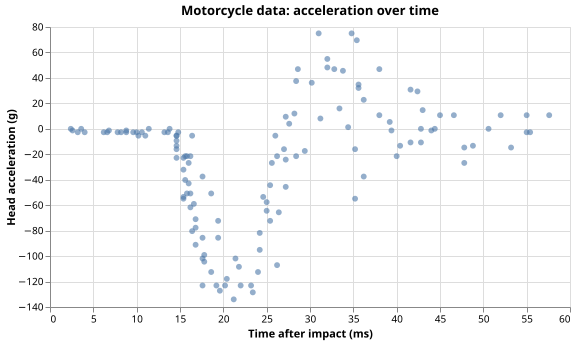

In [1]:
import altair as alt
import numpy as np
import polars as pl
from IPython.display import display

import mboostrs as mb

data = mb.datasets.motorcycle(output="polars")
times = data["times"].to_numpy()
acceleration = data["accel"].to_numpy()
display(data.head())

points = alt.Chart(data).mark_circle(size=35, opacity=0.6).encode(
    x=alt.X("times:Q", title="Time after impact (ms)"),
    y=alt.Y("accel:Q", title="Head acceleration (g)"),
)
points.properties(title="Motorcycle data: acceleration over time", width=520, height=280)

The early readings lie close together; the large negative excursion and
subsequent rebound contain a much wider range of accelerations. Some of that
range comes from the changing mean, so the mean is fitted first and the
remaining variation examined afterwards.

## The mean curve: `gamboost`

`bbs(times, df=6)` is a P-spline base learner: a cubic B-spline basis in time
with a penalty on the differences between neighbouring coefficients. Its
`df=6` sets the penalty so that one update has six effective degrees of
freedom, which lets the fit follow the rapid changes around impact. The
boosting path has 2,000 updates with a step length of 0.1, meaning each update
adds one tenth of the fitted base learner to the model; the stopping point is
selected on ten folds.

These folds hold out individual measurements and score interpolation within
the recorded time range. Repeated times and nearby measurements may occur in
both training and validation portions. The scores serve smoothing choices
within this record and are not evidence of accuracy on independent accidents.

Mean curve: 439 updates selected.


/Users/fcela/src/public_github/mboostrs/python/mboostrs/_workflow.py:191: UserWarning: boosting has undone much of the penalty of 1 learner(s): bbs(times): 14.6 of 24 df after 2000 selections (one step: 5.05). Each selection fits a shrunken step, and the steps add up to the unpenalized fit on the learner's basis, so a penalty's df= no longer sets the term's flexibility. The predictions at this mstop already include that flexibility; the warning changes no fitted value. Choose mstop by cross-validation (cv_risk) rather than fitting this long, because cross-validation scores that flexibility out of fold. penalty_drift() lists every learner. Guide: python -m mboostrs guide fit-and-tune.
  return function(*args, **kwargs)


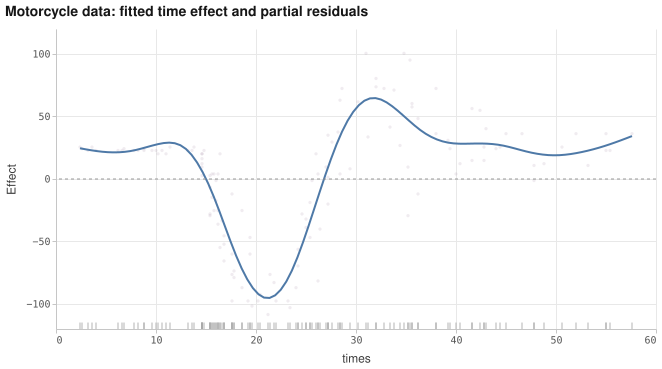

In [2]:
folds = mb.cv_weights(data.height, type="kfold", B=10, seed=5)
mean_path = mb.gamboost(
    "accel ~ bbs(times, df=6)", data=data, family=mb.Gaussian(),
    control=mb.boost_control(mstop=2000, nu=0.1),
)
mean_cv = mean_path.cvrisk(folds=folds)
mean_model = mean_path[:mean_cv.optimal_mstop]
print(f"Mean curve: {mean_cv.optimal_mstop} updates selected.")

mb.plot.plot_partial_effects(mean_model, which="times").properties(
    title="Motorcycle data: fitted time effect and partial residuals",
)

The selected curve uses {eval}`mean_cv.optimal_mstop` updates. The plot shows
the time effect and its partial residuals. With one smooth term, adding the
model's constant offset to the effect gives the mean acceleration curve.

## Residual spread

Residuals are observed acceleration minus the fitted mean. Plotting them
against time removes the fitted trajectory and shows where its remaining
errors are large. A systematic bend would suggest an inadequate mean
curve; a change in vertical spread suggests modelling the standard deviation.

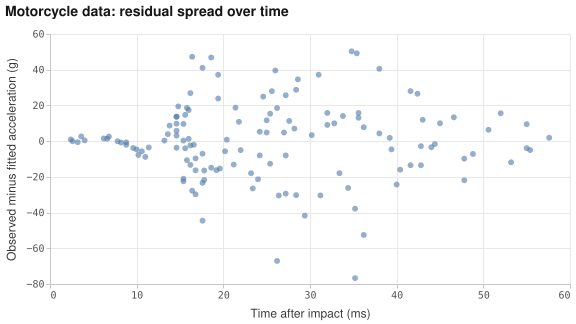

In [3]:
residuals = mean_model.residuals(type="response")
residual_data = data.with_columns(pl.Series("residual", residuals))
alt.Chart(residual_data).mark_circle(size=35, opacity=0.6).encode(
    x=alt.X("times:Q", title="Time after impact (ms)"),
    y=alt.Y("residual:Q", title="Observed minus fitted acceleration (g)"),
).properties(title="Motorcycle data: residual spread over time", width=520, height=250)

The residual cloud is narrow early in the record and wider after impact.
Using one residual standard deviation would give the same interval width at
every time. That calculation is kept as a reference for the location-scale
model.

The constant-width interval below is the fitted mean plus or minus the 95th
standard-normal quantile times the residual standard deviation. It is a
central 90% Gaussian interval that substitutes the estimated mean and standard
deviation for the true ones (a plug-in interval), with no allowance for
uncertainty in either estimate.

In [4]:
from statistics import NormalDist

mean_prediction = mean_model.predict(type="response")
residual_sd = float(np.std(residuals, ddof=1))
normal_cutoff = NormalDist().inv_cdf(0.95)
constant_lower = mean_prediction - normal_cutoff * residual_sd
constant_upper = mean_prediction + normal_cutoff * residual_sd
constant_width = float(2 * normal_cutoff * residual_sd)
print(f"Constant residual SD: {residual_sd:.2f} g; "
      f"central 90% interval width: {constant_width:.1f} g.")

Constant residual SD: 21.64 g; central 90% interval width: 71.2 g.


The resulting width is {eval}`f"{constant_width:.1f}"` g everywhere, including
times where the observations are tightly clustered. The location-scale model
gives the distribution a different standard deviation at each time.

## The scale equation: `GaussianLSS`

A Gaussian location-scale model assumes that acceleration at time $t$ has
mean $\mu(t)$ and standard deviation $\sigma(t)$. `GaussianLSS` (LSS:
location, scale and shape) fits a predictor for each. The `mu` predictor is on the acceleration scale; the
`sigma` predictor is for $\log \sigma$, keeping the standard deviation positive.

The formula dictionary makes both equations explicit. `1` in the scale
formula is an intercept that can update the overall log standard deviation;
`bbs(times, df=6)` allows its value to change smoothly over time.

The two parameters have different units and can require different learning
speeds. This fit uses `stabilization="L2"`, which divides each parameter's
negative gradient by its root mean square, with step lengths 1.0 for `mu` and
0.01 for `sigma`. With these settings the mean predictor fits most of the
trajectory early in the path, and the scale predictor then fits the residual
spread left by the mean.
These numerical settings stay fixed during the stopping search; the final
extension examines their effect.

In [5]:
scale_formulas = {
    "mu": "accel ~ bbs(times, df=6)",
    "sigma": "accel ~ 1 + bbs(times, df=6)",
}
scale_path = mb.gamboostLSS(
    scale_formulas, data=data, family=mb.GaussianLSS(),
    control=mb.boost_control(mstop=8000, nu=0.1),
    stabilization="L2", nu={"mu": 1.0, "sigma": 0.01},
)

Each cycle updates the mean and then the scale. The `nu` dictionary sets a
separate step length for each parameter, replacing the single step length
`nu=0.1` given in `boost_control`, the object that holds the number of
iterations and the step length.

The number of cycles is chosen on the same row folds as the mean model. Each pair
in `grid` gives the stopping budget for `mu` and `sigma`, in that order. Equal
budgets form a diagonal search: both parameters receive the same number of
updates, at their different step lengths.

Selected budgets [mu, sigma]: [4000, 4000]


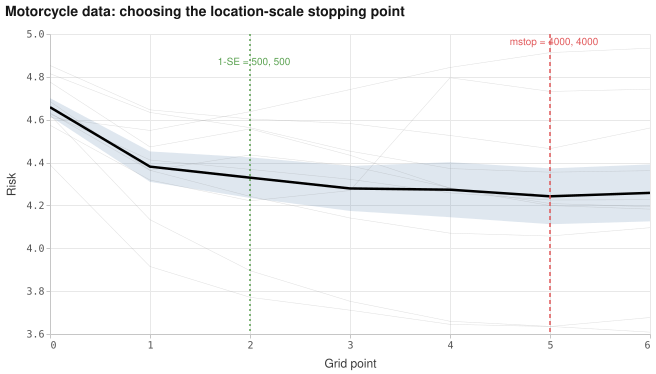

In [6]:
scale_grid = [[m, m] for m in (100, 250, 500, 1000, 2000, 4000, 8000)]
scale_cv = scale_path.cvrisk(folds=folds, grid=scale_grid)
scale_model = scale_path.with_mstop(scale_cv.optimal_mstop)

print(f"Selected budgets [mu, sigma]: {scale_cv.optimal_mstop}")
mb.plot.plot_lss_cvrisk(scale_cv).properties(
    title="Motorcycle data: choosing the location-scale stopping point",
)

The selected budgets are {eval}`scale_cv.optimal_mstop`. Here the risk is
average negative log likelihood: it scores the complete fitted distribution,
including its spread. It cannot be compared numerically with the mean model's
squared-error curve. `with_mstop` refits the distributional model at the
selected budgets and returns the refitted model; for the single-parameter mean
model, slicing the path (`mean_path[:m]`) keeps the first `m` updates for the
same purpose.

A diagonal grid limits the search to equal update counts. The
[distributional model-selection chapter](../methodology/gamlss.ipynb)
explains searches with separate stopping budgets.

## Conditional centiles: `centiles`

`centiles` turns the fitted mean and scale into quantiles. Probabilities 0.05
and 0.95 enclose the central 90% of the fitted conditional distribution;
0.5 gives its median, which equals its mean for a Gaussian model.

Predictions are requested at three times in the observed range. The returned
columns `q5`, `q50` and `q95` are all acceleration in g.

In [7]:
new_times = pl.DataFrame({"times": [6.0, 25.0, 45.0]})
centiles = scale_model.centiles(newdata=new_times, probs=[0.05, 0.5, 0.95])
new_times.hstack(centiles.select("q5", "q50", "q95")).with_columns(
    (pl.col("q95") - pl.col("q5")).alias("90% width (g)"),
)

times,q5,q50,q95,90% width (g)
f64,f64,f64,f64,f64
6.0,-4.657875,-3.143437,-1.628999,3.028876
25.0,-106.237159,-69.723509,-33.209859,73.0273
45.0,-18.525954,0.992806,20.511565,39.037519


Each row describes a distribution at one time, including a central value and
its surrounding spread. These are intervals for acceleration values under the
fitted distribution. A confidence interval for the mean curve would answer a
different question and would need to account for estimation uncertainty.

The same quantiles evaluated on a grid of 200 times give the band in the
figure "Motorcycle data: fitted median and central 90% interval".

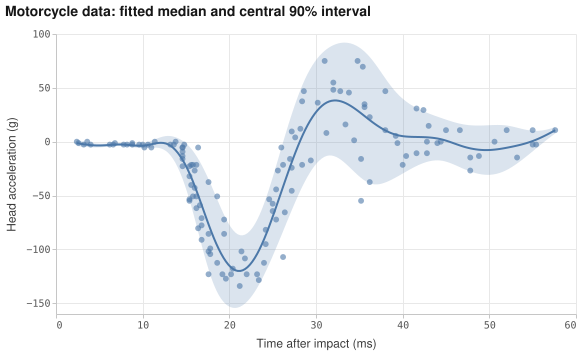

In [8]:
time_grid = pl.DataFrame({"times": np.linspace(times.min(), times.max(), 200)})
grid_centiles = scale_model.centiles(newdata=time_grid, probs=[0.05, 0.5, 0.95])
profile = time_grid.hstack(grid_centiles.select("q5", "q50", "q95"))

base = alt.Chart(profile).encode(x=alt.X("times:Q", title="Time after impact (ms)"))
band = base.mark_area(opacity=0.2).encode(
    y=alt.Y("q5:Q", title="Head acceleration (g)"), y2="q95:Q",
)
median = base.mark_line().encode(y="q50:Q")
(band + median + points).properties(
    title="Motorcycle data: fitted median and central 90% interval", width=520, height=280,
)

The band can narrow and widen with time, whereas the constant-width interval stays the same width at every time. This is the main capability added by the scale equation.
The visible agreement with the fitted observations is descriptive; it does
not establish 90% coverage for a new crash.

The workflow specifies a mean and a scale separately, tunes the distributional fit, and return quantiles at new predictor values. The two
extensions examine the interval and the numerical settings. For an application with independent evaluation folds, see
[](munich_rents_distributional.ipynb).

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | describing the changing trajectory and spread of recorded head acceleration |
| **Observed response** | `accel`, head acceleration after impact |
| **Estimand** | a smooth conditional mean, standard deviation and Gaussian centiles of acceleration over recorded time |
| **Units** | acceleration and interval widths in g; time in milliseconds |
| **Sampling unit** | one recorded acceleration measurement |
| **Dependence** | repeated times and possible dependence within the record; independent crash identifiers are unavailable |
| **Split / resampling unit** | individual measurements, in shared ten-fold row validation |
| **Tuning** | squared error selects mean-model `mstop`; negative log likelihood selects diagonal location-scale budgets with fixed step lengths |
| **Uncertainty** | fitted response spread; interval coverage below is descriptive and estimation uncertainty is not quantified |
| **Claim type** | descriptive within the supplied record, with no claim about independent crashes |
:::

## Extension: interval width by time band

Aggregate coverage can conceal where an interval is too wide or too narrow.
The table compares the constant-width reference with the location-scale
interval in four time bands. Coverage here is the fraction of the training measurements
inside the fitted interval, computed on the rows used to fit the model (an in-sample diagnostic).

In [9]:
fitted_centiles = scale_model.centiles(probs=[0.05, 0.95])
varying_lower = fitted_centiles["q5"].to_numpy()
varying_upper = fitted_centiles["q95"].to_numpy()

edges = [0, 14, 20, 30, 60]
intervals = {
    "constant width": (constant_lower, constant_upper),
    "varying scale": (varying_lower, varying_upper),
}
rows = []
for left, right in zip(edges[:-1], edges[1:]):
    inside = (times > left) & (times <= right)
    for label, (lower, upper) in intervals.items():
        covered = (acceleration[inside] >= lower[inside]) & (acceleration[inside] <= upper[inside])
        rows.append({
            "time band (ms)": f"{left}–{right}", "model": label,
            "n": int(inside.sum()), "coverage": float(covered.mean()),
            "mean width (g)": float(np.mean(upper[inside] - lower[inside])),
        })
interval_check = pl.DataFrame(rows)
interval_check

time band (ms),model,n,coverage,mean width (g)
str,str,i64,f64,f64
"""0–14""","""constant width""",21,1.0,71.196596
"""0–14""","""varying scale""",21,0.904762,6.751704
"""14–20""","""constant width""",38,0.868421,71.196596
"""14–20""","""varying scale""",38,0.894737,63.499845
"""20–30""","""constant width""",31,0.903226,71.196596
"""20–30""","""varying scale""",31,0.935484,78.386318
"""30–60""","""constant width""",43,0.837209,71.196596
"""30–60""","""varying scale""",43,0.930233,73.345261


Read width and coverage together. Covering every observation with a very wide
interval provides little precision, while a narrow interval that misses many
observations understates the spread. The two procedures also estimate their
mean curves differently, so these differences cannot all be attributed to
the scale equation alone. In the first 14 ms the constant interval is 71.2 g
wide and covers all 21 measurements; the location-scale interval is 6.8 g wide
and covers 90.5% of them. After 30 ms the constant interval covers 83.7% and
the location-scale interval 93.0%, at similar widths (71.2 g and 73.3 g).

A fitted probability integral transform (PIT) gives another descriptive check.
For each observed acceleration it computes the fitted distribution's cumulative
probability. Values near zero or one lie in the fitted tails. An appropriate
conditional distribution would produce uniform PIT values on independent
observations; here the observations were used to fit and tune the model.

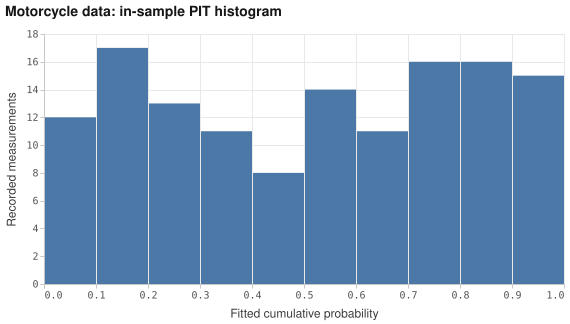

In [10]:
pit = scale_model.pit(random_state=0)
alt.Chart(pl.DataFrame({"PIT": pit})).mark_bar().encode(
    x=alt.X("PIT:Q", bin=alt.Bin(step=0.1, extent=[0, 1]), title="Fitted cumulative probability"),
    y=alt.Y("count():Q", title="Recorded measurements"),
).properties(title="Motorcycle data: in-sample PIT histogram", width=520, height=250)

The histogram helps locate systematic departures from the fitted distribution.
The usual chi-square test of uniformity, which compares observed bin counts with the counts expected under uniform PIT values, does not apply directly to these reused observations: fitting, tuning and possible dependence change the reference distribution the test assumes. Gaussian tails and the small number of measurements
remain constraints on what the outer centiles can establish.

## Extension: parameter learning speeds

A scale model can appear to explain a wide residual cloud while its mean is
still poorly fitted. To examine this, the same model is refitted with equal
parameter step lengths of 0.1 and the same L2 stabilization, tuned on its own
diagonal grid, and its mean fit is compared with its scale.

In [11]:
equal_step_path = mb.gamboostLSS(
    scale_formulas, data=data, family=mb.GaussianLSS(),
    control=mb.boost_control(mstop=8000, nu=0.1), stabilization="L2",
)
equal_step_cv = equal_step_path.cvrisk(folds=folds, grid=scale_grid)
equal_step_model = equal_step_path.with_mstop(equal_step_cv.optimal_mstop)

speed_rows = []
for label, model, cv in (
    ("equal steps", equal_step_model, equal_step_cv),
    ("separate steps", scale_model, scale_cv),
):
    parameters = model.params(type="response")
    speed_rows.append({
        "setting": label, "cycles": cv.optimal_mstop[0],
        "training mean MSE (g²)": float(np.mean((acceleration - parameters["mu"]) ** 2)),
        "largest fitted SD (g)": float(np.max(parameters["sigma"])),
        "ten-fold negative log likelihood": float(np.min(cv.aggregate)),
    })
pl.DataFrame(speed_rows)

setting,cycles,training mean MSE (g²),largest fitted SD (g),ten-fold negative log likelihood
str,i64,f64,f64,f64
"""equal steps""",500,1946.898188,105.02608,4.649857
"""separate steps""",4000,470.022095,36.469074,4.242582


On this record the equal-step fit stops at 500 cycles with a training mean
squared error of 1,947 g² and a largest fitted standard deviation of 105 g. The
separate-step fit stops at 4,000 cycles with 470 g² and 36 g: with the larger
step length for the mean, the mean accounts for more of the trajectory and less
of it is assigned to the scale.
The comparison is a numerical sensitivity check on the same folds used for
tuning; its best score is not an independent performance estimate.

When fitting another response, inspect both the mean curve and the scale, check
whether tuning reaches a search boundary, and investigate parameter step lengths
or a change of response units if one parameter adapts much faster than the other.
The step lengths used here are working settings for this example; another
response may need different ones.